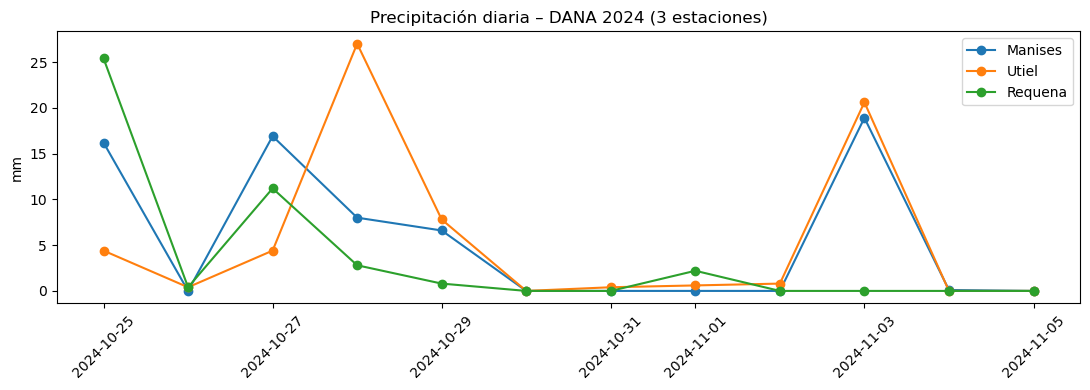

In [9]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ruta = Path("../data/raw/aemet")
estaciones = {"8414A": "Manises", "8293X": "Utiel", "8175": "Requena"}

dfs = []
for codigo, nombre in estaciones.items():
    with open(ruta / f"{codigo}_dana_2024.json", encoding="utf-8") as f:
        d = pd.DataFrame(json.load(f))
    d["fecha"] = pd.to_datetime(d["fecha"])
    d["prec"] = pd.to_numeric(d["prec"].str.replace(",", "."), errors="coerce")
    d["estacion"] = nombre
    dfs.append(d[["fecha", "prec", "estacion"]])

df = pd.concat(dfs, ignore_index=True)

fig, ax = plt.subplots(figsize=(11, 4))
for nombre in estaciones.values():
    sub = df[df["estacion"] == nombre]
    ax.plot(sub["fecha"], sub["prec"], marker="o", label=nombre)
ax.set_title("Precipitación diaria – DANA 2024 (3 estaciones)")
ax.set_ylabel("mm")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()